# GDBN v3: Daily Stock Rankings (Long–Short Portfolio)

Notebook 03 showed the GDBN cannot predict the **level** of tomorrow's returns: most of a day's move is the market moving every stock together, and nobody can predict that. Here we ask an easier question:

> **Which stocks will do better than the others tomorrow?**

This is the **downstream** test from Niu et al.: use the graph to sort stocks, buy the top group, short the bottom group, and measure the **high-minus-low return (HMLR)**.

**Target (excess return):** each stock's return minus the average of the 30 stocks that day:

$$e_i(t) = r_i(t) - \frac{1}{30}\sum_{j} r_j(t)$$

The market move cancels out, so only the **relative** part is left.

**Each day:**
1. Score every stock with a signal (using only data up to yesterday).
2. Rank the 30 stocks.
3. **Buy the top 6, short the bottom 6**, equal weights; hold for one day.

**Signals compared:**

| Signal | Score for each stock |
|---|---|
| **GDBN** | the network's predicted excess return (lasso on all 95 variables yesterday) |
| **GDBN risk-adjusted** | predicted excess return ÷ predicted volatility (HAR), so calm stocks with the same forecast rank higher |
| Reversal (benchmark) | minus yesterday's return: yesterday's losers tend to bounce back |
| Sentiment (benchmark) | yesterday's news sentiment |
| Random (benchmark) | random scores: what luck looks like |

**Metrics:**
- **Rank IC:** each day, the correlation between predicted ranks and actual ranks (Spearman). 0 = no skill; **0.02–0.05 is good in practice**.
- **Long–short return (HMLR):** average daily return of top 6 minus bottom 6, its t-statistic (Newey–West), and the **Sharpe ratio** (return ÷ risk, per year).
- **Turnover and costs:** daily re-ranking trades a lot. The **breakeven cost** is the trading cost per trade that would wipe out the profit.
- **Long only:** top 6 vs simply owning all 30 equally.

**Splits:** choose settings on 2021–2022 (validation); the test years (2023 onward) are **not used in this notebook**; they are evaluated once, later, in a separate final-test notebook.

**Caveat (survivorship bias):** the 30 stocks were chosen because they are large companies **today**. A real investor in 2006 would not have known NVDA would become one of the largest. To limit this, the GDBN score leaves out each stock's average past return, so it cannot just "always buy the past winners."

In [ ]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
from sklearn.linear_model import lasso_path, Lasso
from gdbn_utils import load_data, make_pairs, standardizer, volatility_dataset, har_features, RESULTS

pd.set_option("display.precision", 4)

wide, split, info = load_data()
STOCKS, SECTOR = info["STOCKS"], info["SECTOR"]
SRET = [f"{t}_ret" for t in STOCKS]          # the 30 stocks we rank (ETFs are inputs only)

TOP_N = 6          # buy the top 6, short the bottom 6
COST_BPS = 5       # trading cost per unit traded, in basis points (0.05%)
N_RANDOM = 200     # random portfolios for the luck benchmark
print(f"Ranking {len(SRET)} stocks; inputs = all {wide.shape[1]} variables yesterday")

Ranking 30 stocks; inputs = all 95 variables yesterday


## 1. Pairs, excess returns, and standardization

- $X$: all 95 variables on day $t-1$ (returns, news sentiment, news attention).
- $R$: the 30 stocks' actual returns on day $t$ (used to compute portfolio profits).
- $E$: excess returns on day $t$ (the target).

Standardization uses **training statistics only**.

In [ ]:
X, Y, labels = make_pairs(wide, split)
R = Y[SRET]                                   # actual returns on day t
EXC = R.sub(R.mean(axis=1), axis=0)           # excess return over the 30-stock average
tr, va, te = [(labels == s).values for s in ["train", "validation", "test"]]

def standardize(fit_rows):
    # z-scores using the means and standard deviations of fit_rows only
    mu_x, sd_x = standardizer(X[fit_rows]); mu_e, sd_e = standardizer(EXC[fit_rows])
    return (X - mu_x) / sd_x, (EXC - mu_e) / sd_e, sd_e

Xz, Ez, sd_e = standardize(tr)
print(f"train days: {tr.sum()}, validation days: {va.sum()}, test days: {te.sum()}")
print(f"Check: excess returns sum to 0 each day -> max |sum| = {EXC.sum(axis=1).abs().max():.1e}")

train days: 3707, validation days: 503, test days: 502
Check: excess returns sum to 0 each day -> max |sum| = 9.2e-16


## 2. Ranking tools

- `daily_ic`: rank correlation between a signal and the actual excess returns, one value per day.
- `positions`: +1/6 on the top 6 stocks, −1/6 on the bottom 6, 0 otherwise. Ties (e.g., many stocks with sentiment 0) are broken at random.
- `backtest`: daily long–short return, turnover, costs, and the long-only version.
- `nw_t`: t-statistic with Newey–West standard errors (daily returns are slightly autocorrelated; same idea as the DM test).

In [ ]:
def daily_ic(signal, outcome):
    # Spearman rank correlation across the 30 stocks, one value per day (0 if the signal is flat that day)
    return signal.rank(axis=1).corrwith(outcome.rank(axis=1), axis=1).fillna(0.0)

def positions(signal, top=TOP_N, seed=1):
    ranks = signal.rank(axis=1) + np.random.default_rng(seed).uniform(0, 0.01, signal.shape)  # random tie-break
    order = ranks.rank(axis=1).values
    n = signal.shape[1]
    w = np.where(order > n - top, 1 / top, np.where(order <= top, -1 / top, 0.0))
    return pd.DataFrame(w, index=signal.index, columns=signal.columns)

def nw_t(x, lags=5):
    # t-statistic of the mean with Newey-West (HAC) standard errors
    x = np.asarray(x, dtype=float); n = len(x); xc = x - x.mean()
    var = xc @ xc / n
    for k in range(1, lags + 1):
        var += 2 * (1 - k / (lags + 1)) * (xc[k:] @ xc[:-k]) / n
    return x.mean() / np.sqrt(var / n) if var > 0 else np.nan

def backtest(signal, rows, seed=1):
    sig, ret = signal.loc[rows], R.loc[rows]
    w = positions(sig, seed=seed)
    gross = (w * ret).sum(axis=1)                                # long-short daily return
    turnover = w.diff().abs().sum(axis=1)
    turnover.iloc[0] = w.iloc[0].abs().sum()                    # day 1: build the portfolio
    net = gross - turnover * COST_BPS / 1e4
    long_only = ret.where(w > 0).mean(axis=1) - ret.mean(axis=1) # top 6 minus owning all 30
    return {"gross": gross, "net": net, "turnover": turnover, "long_only": long_only,
            "ic": daily_ic(sig, EXC.loc[rows]), "w": w}

def max_drawdown(daily):
    wealth = (1 + daily).cumprod()
    return (wealth / wealth.cummax() - 1).min()

def summary(bt):
    g, n = bt["gross"], bt["net"]
    return pd.Series({
        "IC mean": bt["ic"].mean(),
        "IC t": nw_t(bt["ic"]),
        "IC>0 days": (bt["ic"] > 0).mean(),
        "LS bps/day": g.mean() * 1e4,
        "LS t": nw_t(g),
        "Sharpe gross": g.mean() / g.std() * np.sqrt(252),
        "Sharpe net": n.mean() / n.std() * np.sqrt(252),
        "turnover/day": bt["turnover"].mean(),
        "breakeven bps": g.mean() / bt["turnover"].mean() * 1e4,
        "max drawdown": max_drawdown(g),
        "top6 - all30 bps/day": bt["long_only"].mean() * 1e4,
    })
def buy_hold_row(daily):
    # Buy-and-hold comparison (no trading, so no costs): only the return and risk columns apply
    return pd.Series({"LS bps/day": daily.mean() * 1e4, "LS t": nw_t(daily),
                      "Sharpe gross": daily.mean() / daily.std() * np.sqrt(252),
                      "Sharpe net": daily.mean() / daily.std() * np.sqrt(252), "max drawdown": max_drawdown(daily)})

def add_market_rows(tab, rows):
    tab.loc["S&P 500 (SPY, buy & hold)"] = buy_hold_row(Y.loc[rows, "SPY_ret"])
    tab.loc["All 30 stocks (equal weight)"] = buy_hold_row(R.loc[rows].mean(axis=1))
    return tab
print("tools ready")

tools ready


## 3. The GDBN signal: one lasso per stock, λ chosen for **ranking**

For each stock, a lasso predicts tomorrow's excess return from **all 95 variables yesterday**. A nonzero weight is an arrow (yesterday → today), as in notebook 03.

**Choosing λ.** In notebook 03, λ was chosen to minimize prediction error, and the 1-SE λ kept **no** arrows into returns. Ranking only needs the **order** to be right, so here one shared λ (the same for every stock, which is fair because all variables are z-scores) is chosen to **maximize the validation rank IC**. For comparison, the notebook-03 rule (best λ by error, chosen per stock) is kept too.

**Score = the dynamic part only:** the prediction without the stock's average past excess return (see the survivorship caveat), converted back to return units.

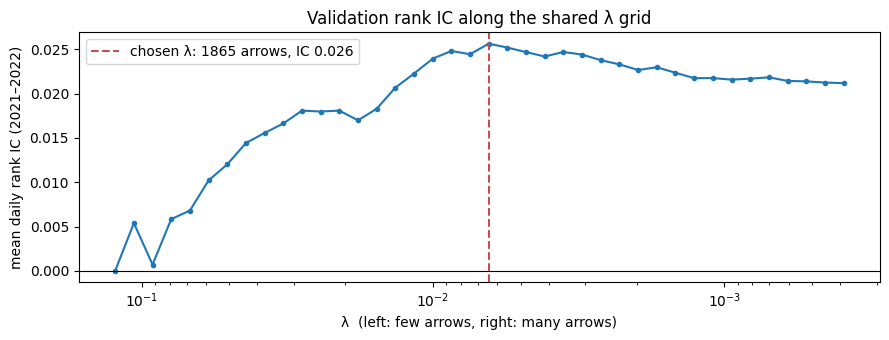

λ by IC : 1,865 arrows into the 30 stocks
λ by MSE: 581 arrows; stocks with no arrows at all: 10 of 30


In [ ]:
Xtr = Xz.values[tr]
xm = Xtr.mean(axis=0)
Xc = Xz.values - xm
alpha_max = max(np.abs((Xtr - xm).T @ (Ez[c].values[tr] - Ez[c].values[tr].mean())).max() / tr.sum() for c in SRET)
ALPHAS = alpha_max * np.logspace(0, -2.5, 40)               # shared λ grid, largest (no arrows) first

coefs = np.zeros((len(SRET), X.shape[1], len(ALPHAS)))     # stock x input x λ
for i, c in enumerate(SRET):
    y = Ez[c].values[tr]
    _, coefs[i], _ = lasso_path(Xtr - xm, y - y.mean(), alphas=ALPHAS)

def gdbn_signal(W):
    # W: (30 stocks x 95 inputs) lasso weights -> predicted excess return (dynamic part), in return units
    return pd.DataFrame(Xc @ W.T, index=X.index, columns=SRET) * sd_e.values

ic_val, mse_val, edges = [], [], []
for k in range(len(ALPHAS)):
    s = gdbn_signal(coefs[:, :, k])
    ic_val.append(daily_ic(s.loc[va], EXC.loc[va]).mean())
    edges.append(int((coefs[:, :, k] != 0).sum()))
ic_val = np.array(ic_val)
k_ic = int(np.argmax(ic_val))

# Notebook-03 rule for comparison: per stock, the λ with the lowest validation error
k_mse = []
for i, c in enumerate(SRET):
    pz = Xc[va] @ coefs[i]                                   # (val days x λ), z units
    k_mse.append(int(np.argmin(((Ez[c].values[va][:, None] - pz) ** 2).mean(axis=0))))
W_ic = coefs[:, :, k_ic]
W_mse = np.stack([coefs[i, :, k] for i, k in enumerate(k_mse)])

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.semilogx(ALPHAS, ic_val, "o-", ms=3)
ax.axvline(ALPHAS[k_ic], color="#c44e52", ls="--", label=f"chosen λ: {edges[k_ic]} arrows, IC {ic_val[k_ic]:.3f}")
ax.axhline(0, color="black", lw=0.8)
ax.invert_xaxis(); ax.set_xlabel("λ  (left: few arrows, right: many arrows)"); ax.set_ylabel("mean daily rank IC (2021–2022)")
ax.set_title("Validation rank IC along the shared λ grid"); ax.legend(); plt.tight_layout(); plt.show()
print(f"λ by IC : {edges[k_ic]:,} arrows into the 30 stocks")
print(f"λ by MSE: {int((W_mse != 0).sum()):,} arrows; stocks with no arrows at all: {int(((W_mse != 0).sum(axis=1) == 0).sum())} of 30")

**Reading the plot:** at the far left (huge λ) there are no arrows, so the signal is flat and the IC is 0. Moving right adds arrows. If the IC rises above 0 and then falls, the left part of the curve is **underfitting** and the right part is **overfitting**. Picking the peak uses the validation year, so the validation IC of the chosen λ is a little optimistic; the test set gives the honest number.

## 4. Predicted volatility (for the risk-adjusted signal)

The risk-adjusted score divides the predicted excess return by each stock's **predicted volatility** for tomorrow, from the **HAR** model of notebook 04 (yesterday, past week, past month of $\log|r|$). HAR is used here instead of the full volatility GDBN to keep this notebook self-contained; the GDBN was only about 1% better than HAR.

In [ ]:
voldata, VOL = volatility_dataset(wide, info)
SVOL = [f"{t}_vol" for t in STOCKS]
HAR_X = pd.concat([voldata[SVOL].shift(1).add_suffix("@t-1"), har_features(voldata, SVOL).shift(1)], axis=1).reindex(X.index)
LOGVOL = voldata[SVOL].reindex(X.index)

def har_vol(fit_rows):
    # Predicted size of tomorrow's move for each stock: exp(HAR forecast of log|r|), fit on fit_rows
    out = {}
    for t in STOCKS:
        cols = [f"{t}_vol@t-1", f"{t}_vol_week", f"{t}_vol_month"]
        ok = HAR_X[cols].notna().all(axis=1).values
        A = np.column_stack([np.ones(len(HAR_X)), HAR_X[cols].values])
        coef, *_ = np.linalg.lstsq(A[fit_rows & ok], LOGVOL[f"{t}_vol"].values[fit_rows & ok], rcond=None)
        out[f"{t}_ret"] = np.exp(A @ coef)
    return pd.DataFrame(out, index=X.index)

pred_vol = har_vol(tr)
print("predicted daily volatility (median across stocks, validation):", f"{pred_vol.loc[va].median().median():.4f}")

predicted daily volatility (median across stocks, validation): 0.0086


## 5. All signals and the random benchmark (validation 2021–2022)

Random portfolios show what **luck** looks like: if a signal's Sharpe ratio is inside the random range, it is not distinguishable from chance.

In [ ]:
def make_signals(W_main, W_alt, vol):
    gd = gdbn_signal(W_main)
    sig = {
        "GDBN (λ by IC)": gd,
        "GDBN risk-adj": gd / vol,
        "GDBN (λ by MSE)": gdbn_signal(W_alt) if W_alt is not None else None,
        "Reversal": -X[SRET],
        "Sentiment": X[[f"{t}_sent" for t in STOCKS]].set_axis(SRET, axis=1),
    }
    return {k: v for k, v in sig.items() if v is not None}

signals = make_signals(W_ic, W_mse, pred_vol)
bts = {name: backtest(s, va) for name, s in signals.items()}
table = pd.DataFrame({name: summary(bt) for name, bt in bts.items()}).T

rand_rng = np.random.default_rng(0)
rand = pd.DataFrame([summary(backtest(pd.DataFrame(rand_rng.normal(size=R.shape), index=R.index, columns=SRET), va, seed=s))
                     for s in range(N_RANDOM)])
table.loc["Random (median)"] = rand.median()
table = add_market_rows(table, va)
lo, hi = rand["Sharpe gross"].quantile([0.025, 0.975])
print(f"Random portfolios: 95% of gross Sharpe ratios fall in [{lo:.2f}, {hi:.2f}]")
table

Random portfolios: 95% of gross Sharpe ratios fall in [-1.29, 1.32]


,IC mean,IC t,IC>0 days,LS bps/day,LS t,Sharpe gross,Sharpe net,turnover/day,breakeven bps,max drawdown,top6 - all30 bps/day
GDBN (λ by IC),0.0256,1.9950,0.5249,13.9248,2.1079,1.4668,-0.1041,2.9828,4.6684,-0.1995,8.4760
GDBN risk-adj,0.0226,1.7886,0.5408,13.1237,2.2021,1.4916,-0.2152,3.0040,4.3688,-0.1444,7.7651
GDBN (λ by MSE),0.0433,3.6271,0.5805,27.2059,4.1801,3.1023,1.6698,2.5129,10.8264,-0.1979,14.7556
Reversal,-0.0049,-0.2966,0.5050,-0.9131,-0.1175,-0.0827,-1.4837,3.0941,-0.2951,-0.3667,-2.5636
Sentiment,0.0024,0.2311,0.5109,-4.7103,-0.9046,-0.6797,-2.7306,2.8410,-1.6580,-0.3418,-2.0304
Random (median),0.0007,0.0878,0.5010,0.3775,0.0824,0.0607,-2.5411,3.1981,0.1183,-0.2143,-0.0587
"S&P 500 (SPY, buy & hold)",NaN,NaN,NaN,1.7872,0.3498,0.2314,0.2314,NaN,NaN,-0.2450,NaN
All 30 stocks (equal weight),NaN,NaN,NaN,8.9805,1.7948,1.2002,1.2002,NaN,NaN,-0.1519,NaN


**How to read the table:**
- **IC mean / IC t:** ranking skill and whether it is significant (|t| > 2 ≈ p < 0.05).
- **LS bps/day:** average daily profit of the long–short portfolio (1 bp = 0.01%). **LS t** tests whether it is above 0.
- **Sharpe gross / net:** profit per unit of risk, per year, before / after costs of `COST_BPS` per unit traded.
- **turnover/day:** the most possible is 4 (sell all 6 longs, buy 6 new, cover all 6 shorts, short 6 new).
- **breakeven bps:** the trading cost at which the profit would be zero. Large-cap stocks cost roughly 1–5 bps to trade.
- **top6 − all30:** the long-only version vs owning all 30 equally.

**S&P 500 and equal-weight rows (comparison):** simply buying and holding SPY, or all 30 stocks equally. Only the return, Sharpe, and drawdown columns apply (no ranking, almost no trading). The long–short portfolio is **market-neutral** (its gains do not depend on whether the market goes up), while buy-and-hold carries full market risk, so **Sharpe** (return per unit of risk) is the fair way to compare them. For reference, the S&P 500's long-run Sharpe ratio is roughly 0.4–0.6; validation covers a bull year (2021) and a bear year (2022).

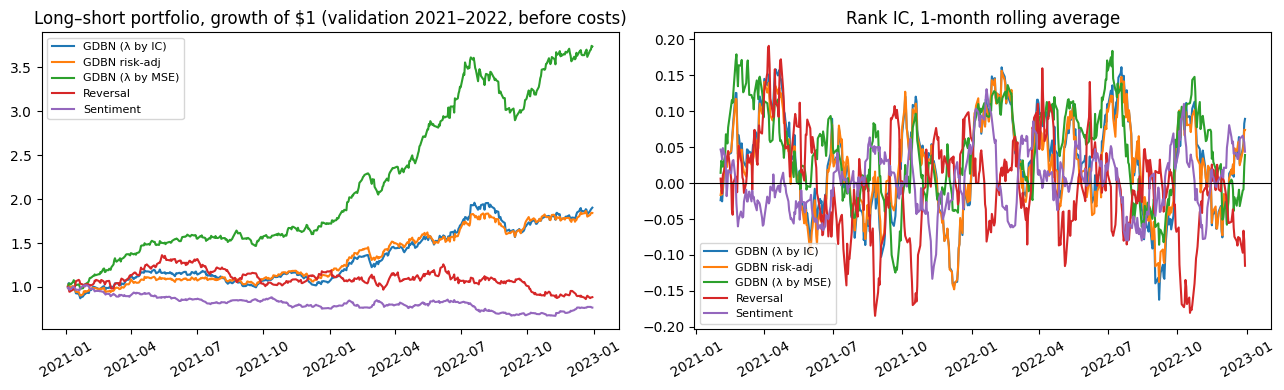

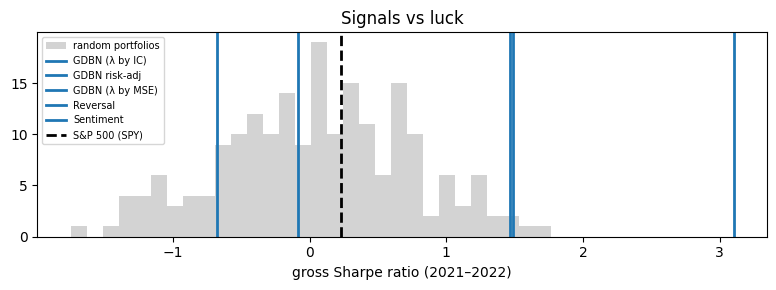

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name, bt in bts.items():
    axes[0].plot((1 + bt["gross"]).cumprod(), label=name)
    axes[1].plot(bt["ic"].rolling(21).mean(), label=name)
axes[0].set_title("Long–short portfolio, growth of $1 (validation 2021–2022, before costs)")
axes[1].set_title("Rank IC, 1-month rolling average"); axes[1].axhline(0, color="black", lw=0.8)
for ax in axes:
    ax.legend(fontsize=8); ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(rand["Sharpe gross"], bins=30, color="lightgray", label="random portfolios")
for name, row in table.loc[list(bts)].iterrows():
    ax.axvline(row["Sharpe gross"], lw=2, label=name)
ax.axvline(table.loc["S&P 500 (SPY, buy & hold)", "Sharpe gross"], color="black", ls="--", lw=2, label="S&P 500 (SPY)")
ax.set_xlabel("gross Sharpe ratio (2021–2022)"); ax.set_title("Signals vs luck"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

## 5b. Robustness: is the GDBN just betting on sectors or overfitting?

Three checks on the GDBN signals:
1. **Average position by sector:** if the portfolio were always long one sector (e.g., energy, which soared in 2021–2022) and short another, the "skill" would just be a lucky sector bet.
2. **Sector-neutral version:** remove each sector's average score every day, so the portfolio can only pick stocks **within** sectors. What survives is stock-level skill; what disappears was skill at choosing **between** sectors.
3. **Training vs validation IC:** how much better the model looks on the data it was fit on (the overfitting gap).

In [ ]:
sec = pd.Series({c: SECTOR[c[:-4]] for c in SRET})
checks = {}
for name in ["GDBN (λ by IC)", "GDBN risk-adj", "GDBN (λ by MSE)"]:
    s = signals[name]
    w = bts[name]["w"]
    print(f"{name}: average daily weight by sector (validation):",
          {k: round(v, 3) for k, v in w.T.groupby(sec).sum().T.mean().items()})
    neutral = s.sub(s.T.groupby(sec).transform("mean").T)          # score relative to its sector that day
    sn, trn = summary(backtest(neutral, va)), summary(backtest(s, tr))
    checks[name] = {"IC (validation)": table.loc[name, "IC mean"], "IC sector-neutral": sn["IC mean"],
                    "IC t sector-neutral": sn["IC t"], "Sharpe sector-neutral": sn["Sharpe gross"],
                    "IC (training, in-sample)": trn["IC mean"]}
pd.DataFrame(checks).T

GDBN (λ by IC): average daily weight by sector (validation): {'Banks': 0.028, 'Energy': -0.001, 'Healthcare': -0.047, 'Industrials': 0.006, 'Staples': -0.066, 'Tech': 0.08}
GDBN risk-adj: average daily weight by sector (validation): {'Banks': 0.036, 'Energy': 0.003, 'Healthcare': -0.042, 'Industrials': 0.005, 'Staples': -0.063, 'Tech': 0.061}
GDBN (λ by MSE): average daily weight by sector (validation): {'Banks': -0.002, 'Energy': 0.016, 'Healthcare': -0.043, 'Industrials': 0.012, 'Staples': -0.045, 'Tech': 0.062}


,IC (validation),IC sector-neutral,IC t sector-neutral,Sharpe sector-neutral,"IC (training, in-sample)"
GDBN (λ by IC),0.0256,0.0108,1.7160,0.6979,0.1054
GDBN risk-adj,0.0226,0.0107,1.6914,1.0379,0.1022
GDBN (λ by MSE),0.0433,0.0208,2.9058,2.1823,0.0603


**Reading the checks:**
- Average sector weights near 0 mean there is **no fixed sector bet**; the portfolio moves between sectors from day to day.
- If the IC drops a lot when sector-neutral, most of the skill is **choosing between sectors** (e.g., "energy will beat tech tomorrow"), not stocks within a sector.
- Training IC far above validation IC is the usual overfitting gap. What matters is that validation (and later test) stays above 0.
- Several signals and λ rules were tried on the same years (2021–2022), so the best validation number is **optimistic**. This is why the test set is used once, for the signal committed to in advance.

## 6. What is the GDBN using?

The arrows into the 30 stocks at the chosen λ, grouped by the **type** of input yesterday and whether it is the stock's **own** variable or **another** variable (a cross-stock or news link).

In [ ]:
ticker, kind = info["ticker"], info["kind"]
i_idx, j_idx = np.nonzero(W_ic)
E = pd.DataFrame({"source (t-1)": X.columns[j_idx], "target (t)": [SRET[i] for i in i_idx], "weight": W_ic[i_idx, j_idx]})
E["src_kind"] = E["source (t-1)"].map(kind)
E["link"] = np.where(E["source (t-1)"].map(ticker) == E["target (t)"].map(ticker), "own", "cross")
E["same sector"] = E["source (t-1)"].map(ticker).map(SECTOR) == E["target (t)"].map(ticker).map(SECTOR)
print(E.groupby(["src_kind", "link"]).size().unstack(fill_value=0).to_string(), "\n")
own_ret = E[(E["src_kind"] == "ret") & (E["link"] == "own")]
print(f"own-return arrows: {len(own_ret)}, of which negative (reversal): {(own_ret['weight'] < 0).sum()}")
print("\nStrongest arrows:")
E.reindex(E["weight"].abs().sort_values(ascending=False).index)[["source (t-1)", "target (t)", "weight", "src_kind", "link"]].head(15)

link      cross  own
src_kind            
attn        555   25
ret         672   24
sent        568   21 

own-return arrows: 24, of which negative (reversal): 12

Strongest arrows:


,source (t-1),target (t),weight,src_kind,link
503,MS_ret,GS_ret,0.2509,ret,cross
563,GS_ret,MS_ret,-0.2169,ret,cross
502,GS_ret,GS_ret,-0.1921,ret,own
691,GS_ret,C_ret,-0.1701,ret,cross
1243,GS_ret,PEP_ret,0.1549,ret,cross
564,MS_ret,MS_ret,0.1542,ret,own
1244,MS_ret,PEP_ret,-0.1436,ret,cross
1188,CVX_ret,KO_ret,0.1429,ret,cross
1619,GS_ret,MRK_ret,0.1401,ret,cross
561,JPM_ret,MS_ret,0.1367,ret,cross


## 7. "What to buy tomorrow"

Score the **latest day in the data** with the chosen signal and print the ranking. This uses only inputs (no outcomes), so it does not touch the test results.

To use this for a real day, re-run `pull_data.py` through yesterday and refit on all the data. This is a **research output** for the thesis, not trading advice: with 30 stocks and one year of validation, the evidence is thin.

In [ ]:
SIGNAL_FOR_LIST = "GDBN (λ by IC)"     # change after looking at the validation table

last_x = wide.iloc[[-1]]                                         # the most recent day's 95 variables
last_xz = ((last_x - standardizer(X[tr])[0]) / standardizer(X[tr])[1]).values - xm
score = pd.Series((last_xz @ W_ic.T).ravel() * sd_e.values, index=SRET)
if SIGNAL_FOR_LIST == "GDBN risk-adj":
    score = score / pred_vol.iloc[-1]   # (approximation: uses the last available volatility forecast)
ranked = (pd.DataFrame({"ticker": [c[:-4] for c in score.index], "predicted excess (bps)": score.values * 1e4})
          .assign(sector=lambda d: d["ticker"].map(SECTOR))
          .sort_values("predicted excess (bps)", ascending=False).reset_index(drop=True))
ranked["action"] = np.where(ranked.index < TOP_N, "BUY", np.where(ranked.index >= len(ranked) - TOP_N, "SHORT", "-"))
print(f"Ranking for the trading day after {wide.index[-1].date()} ({SIGNAL_FOR_LIST}):")
ranked

Ranking for the trading day after 2024-12-31 (GDBN (λ by IC)):


,ticker,predicted excess (bps),sector,action
0,BA,28.2720,Industrials,BUY
1,SLB,15.8854,Energy,BUY
2,XOM,15.7524,Energy,BUY
3,AAPL,13.7482,Tech,BUY
4,UNH,13.0578,Healthcare,BUY
5,CAT,10.2456,Industrials,BUY
6,KO,9.9815,Staples,-
7,WFC,6.3845,Banks,-
8,PEP,4.1231,Staples,-
9,PFE,3.7045,Healthcare,-


## 8. Save results

In [ ]:
RESULTS.mkdir(parents=True, exist_ok=True)
table.to_csv(RESULTS / "rank_validation_results.csv")
pd.DataFrame(W_ic, index=SRET, columns=X.columns).to_csv(RESULTS / "rank_gdbn_W_ic.csv")
E.to_csv(RESULTS / "rank_gdbn_edges_ic.csv", index=False)
pd.Series({"alpha_ic": ALPHAS[k_ic], "edges": edges[k_ic], "val_ic": ic_val[k_ic]}).to_csv(RESULTS / "rank_gdbn_chosen_alpha.csv")
print("Saved to", RESULTS)

Saved to /Users/max_lovinger/Documents/Thesis/CoreFragment/data/results
